In [1]:
# # Session 10.7 — Heatmaps & Correlation Analysis
# # આજે આપણે Seaborn માં Heatmap અને Correlation Analysis શીખીશું. Data Science માં આ ખૂબ જ ઉપયોગી topic છે, કારણ કે ઘણી વખત dataset માં 10, 20 કે 50 numerical columns હોય છે. દરેક column વચ્ચેનો સંબંધ અલગ-અલગ chart થી જોવાને બદલે આપણે એક જ Correlation Matrix અને Heatmap દ્વારા ઝડપથી સમજી શકીએ છીએ.

# # આ session માં આપણે શીખીશું:
# # 1. Correlation શું છે?
# # 2. Positive, negative અને zero correlation.
# # 3. Pandas થી correlation matrix બનાવવી.
# # 4. sns.heatmap() નો ઉપયોગ.
# # 5. annot, cmap, vmin, vmax, center જેવા parameters.
# # 6. Student dataset અને business dataset પર practical.
# # 7. Heatmap નું યોગ્ય interpretation અને common mistakes.
# # 1. Correlation શું છે?
# # Correlation એટલે બે numerical variables વચ્ચેનો સંબંધ કેટલો અને કઈ દિશામાં છે તેનું માપ.

# # Correlation coefficient સામાન્ય રીતે \(-1\) થી \(+1\) વચ્ચે હોય છે.

# +1
# Perfect positive correlation
# એક variable વધે ત્યારે બીજું પણ સતત પ્રમાણમાં વધે છે.

# 0
# No linear correlation
# Variables વચ્ચે સ્પષ્ટ linear relationship દેખાતો નથી. Nonlinear relationship છતાં હોઈ શકે.

# −1
# Perfect negative correlation
# એક variable વધે ત્યારે બીજું સતત પ્રમાણમાં ઘટે છે.

# Correlation ની absolute value	સામાન્ય અર્થ
# 0.00–0.19	ખૂબ નબળો linear સંબંધ
# 0.20–0.39	નબળો સંબંધ
# 0.40–0.59	મધ્યમ સંબંધ
# 0.60–0.79	મજબૂત સંબંધ
# 0.80–1.00	ખૂબ મજબૂત સંબંધ

In [2]:
# 2. Setup અને Student Dataset
# VS Code માં Jupyter Notebook ખોલો. જો libraries પહેલાંથી installed ન હોય તો:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = {
    "Student": [
        "Amit", "Neha", "Ravi", "Pooja", "Karan",
        "Meera", "Jay", "Priya", "Rahul", "Nisha",
        "Dev", "Riya"
    ],
    "Python": [85, 92, 70, 88, 65, 95, 78, 82, 90, 86, 73, 96],
    "SQL": [78, 88, 75, 90, 68, 92, 80, 85, 84, 89, 72, 94],
    "Maths": [80, 91, 72, 85, 66, 93, 76, 84, 88, 87, 75, 95],
    "StudyHours": [4, 7, 2, 6, 2, 8, 3, 5, 6, 5, 3, 9]
}

df = pd.DataFrame(data)

print(df.head())

  Student  Python  SQL  Maths  StudyHours
0    Amit      85   78     80           4
1    Neha      92   88     91           7
2    Ravi      70   75     72           2
3   Pooja      88   90     85           6
4   Karan      65   68     66           2


In [ ]:
correlation_matrix = df[
    ["Python", "SQL", "Maths", "StudyHours"]
].corr()

print(correlation_matrix.round(2))

# અહીં:
# - .corr() numerical variables વચ્ચેનો correlation ગણાવે છે.
# - .round(2) values ને બે decimal places સુધી બતાવે છે.
# - Student column સામેલ નથી, કારણ કે તે text છે.

            Python   SQL  Maths  StudyHours
Python        1.00  0.92   0.98        0.95
SQL           0.92  1.00   0.94        0.91
Maths         0.98  0.94   1.00        0.96
StudyHours    0.95  0.91   0.96        1.00


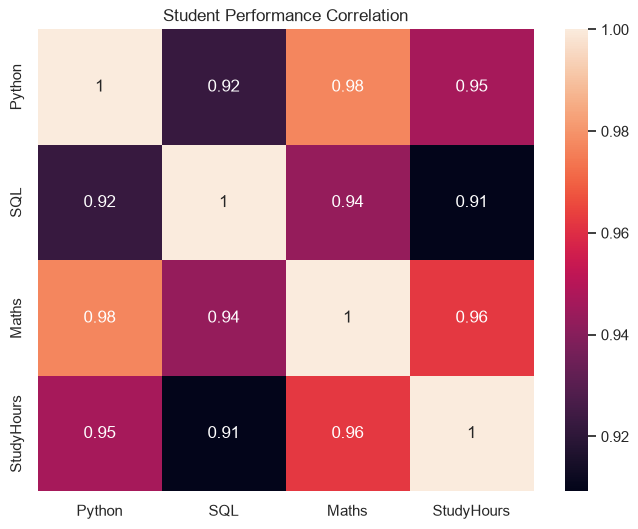

In [ ]:
# 4. sns.heatmap() — પ્રથમ Heatmap
# હવે આ matrix ને રંગીન chart માં ફેરવીએ
correlation_matrix = df[
    ["Python", "SQL", "Maths", "StudyHours"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True
)

plt.title("Student Performance Correlation")
plt.show()

# Code / Parameter	કામ
# plt.figure(figsize=(8, 6))	Chart નું કદ નક્કી કરે છે
# sns.heatmap()	Matrix ને રંગીન grid માં દર્શાવે છે
# annot=True	દરેક cell માં correlation value લખે છે
# plt.title()	Chart નું title આપે છે
# plt.show()	Chart દર્શાવે છે

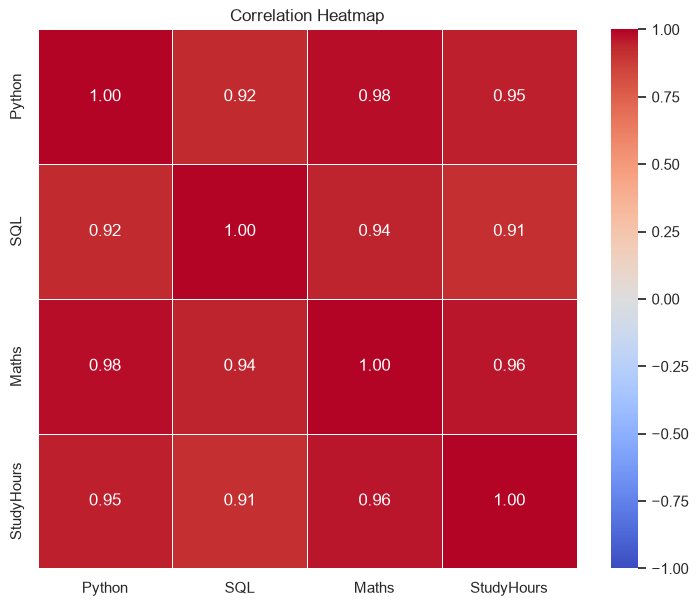

In [ ]:
# 5. Heatmap ના મહત્વના Parameters
# હવે chart ને વધુ professional બનાવીએ.
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True, # cell value add
    fmt=".2f", # value tow decimal 
    cmap="coolwarm",  #Diverging color palette વાપરે છે
    vmin=-1, #Color scale ની minimum value
    vmax=1, #Color scale ની maximum value
    center=0, #Zero ને color scale નું center બનાવે છે
    linewidths=0.5, #Cells વચ્ચેની boundary ની જાડાઈ
    square=True, #Cells ને square બનાવવાનો પ્રયાસ કરે છે
    cbar=True
)

plt.title("Correlation Heatmap")
plt.show()

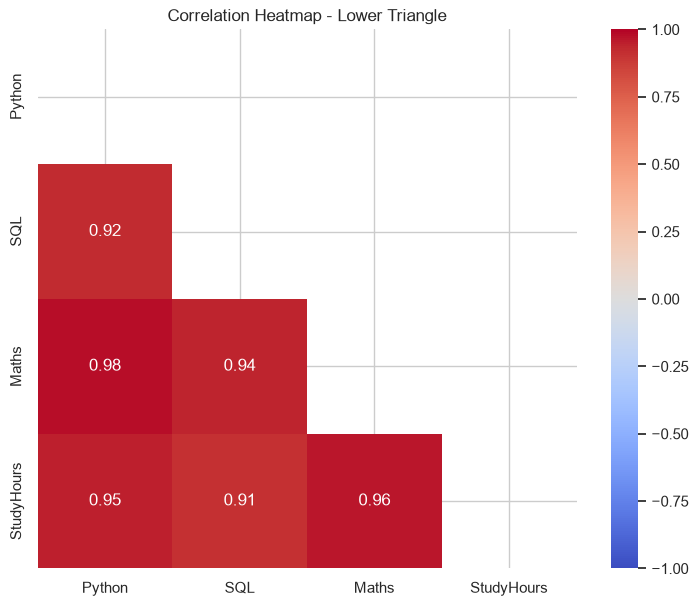

In [ ]:
# 6. ફક્ત ઉપરનો અડધો ભાગ બતાવવો
# Correlation matrix માં upper અને lower triangle માં એક જ values ફરીથી આવે છે. મોટા dataset માં duplicate માહિતી દૂર કરવા માટે mask વાપરી શકાય છે.

mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    mask=mask, # mask karela cell chupave che
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Heatmap - Lower Triangle")
plt.show()

# np.ones_like() matrix ના કદની boolean બનાવવા માટે ઉપયોગમાં લેવાયેલી શરૂઆતની array બનાવે છે.
# np.triu() upper triangle માટે mask બનાવે છે.
# mask=mask mask કરેલા cells ને છુપાવે છે.

# આથી diagonal સહિત upper triangle છુપાઈ જશે અને lower triangle દેખાશે.

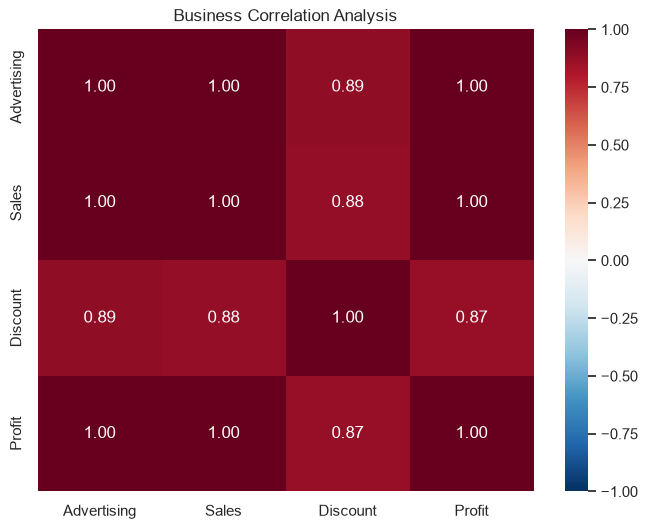

In [ ]:
# 7. Business Practical — Sales અને Profit
# હવે business data પર correlation analysis કરીએ.

business_data = {
    "Advertising": [5, 8, 10, 12, 15, 18, 20, 22, 25, 30],
    "Sales":       [20, 25, 28, 35, 38, 42, 48, 50, 58, 65],
    "Discount":    [2, 5, 3, 8, 6, 10, 7, 12, 9, 15],
    "Profit":      [4, 6, 7, 8, 10, 11, 13, 14, 16, 18]
}

business_df = pd.DataFrame(business_data)

business_corr = business_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    business_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r", 
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Business Correlation Analysis")
plt.show()

# આ chart માંથી શું સમજવું?
# - Advertising અને Sales વચ્ચેનો correlation જુઓ.
# - Sales અને Profit વચ્ચેનો સંબંધ તપાસો.
# - Discount બીજા variables સાથે કેવી રીતે સંબંધિત છે તે જુઓ.
# - વધુ positive correlation ધરાવતી જોડી business investigation માટે ઉપયોગી હોઈ શકે છે.
# - Negative correlation હોય તો variables વિરુદ્ધ દિશામાં બદલાતા હોવાનો linear pattern હોઈ શકે છે.


In [ ]:
# 8. Missing Values અને Correlation
# વાસ્તવિક datasets માં કેટલીક values missing હોઈ શકે છે. ઉદાહરણ:

df_missing = df.copy()

df_missing.loc[0, "SQL"] = np.nan

corr_missing = df_missing[
    ["Python", "SQL", "Maths", "StudyHours"]
].corr()

print(corr_missing.round(2))

# pandas નું .corr() સામાન્ય રીતે દરેક pair માટે ઉપલબ્ધ non-missing observations નો ઉપયોગ કરે છે. એટલે જુદી-જુદી pairs ના correlation જુદી સંખ્યાના observations પરથી ગણાયેલા હોઈ શકે છે.

            Python   SQL  Maths  StudyHours
Python        1.00  0.95   0.98        0.95
SQL           0.95  1.00   0.95        0.91
Maths         0.98  0.95   1.00        0.96
StudyHours    0.95  0.91   0.96        1.00


In [ ]:
# 10. Assignment Checklist
# Practical Progress
# 0/7

# [ ] Student dataset ની correlation matrix બનાવો.
# [ ] annot=True અને fmt='.2f' સાથે heatmap બનાવો.
# [ ] coolwarm અને Blues palettes ની સરખામણી કરો.
# [ ] vmin=-1, vmax=1 અને center=0 વાપરો.
# [ ] Mask વાપરીને matrix નો એક triangle છુપાવો.
# [ ] Business dataset માં સૌથી વધુ positive અને negative correlation શોધો.
# [ ] Correlation પરથી શું કહી શકાય અને શું સાબિત થતું નથી તે લખો.
# Notebook માં tasks પૂર્ણ થતાં checkbox પસંદ કરો.
